# Hands-on: a Baltic SES digital twin in 60 minutes
### Fisheries + offshore wind + the public — the *Case-example II* model on real data

**SEAtwins Symposium training · SEADOTs (Horizon 101156488)**

We take the small social–ecological model from the Excel workbook (fish biomass *x*, windmills *w*, harvest *q*, investment *Iw*) and run it for a real case:

* **Fish stock:** Baltic sprat, *spr.27.22-32* — ICES 2025 assessment (SSB, catches, reference points)
* **Windmills:** the Polish offshore wind pipeline in the Baltic — national reporting (Aug 2026) and EMODnet Human Activities
* **Prices:** Polish sprat first-sale price (EUMOFA) and the Dec 2025 Polish offshore wind auction price

| Time | Part | You do |
|---|---|---|
| 0–5 min | 0. Setup | Run the first cells |
| 5–15 | 1. The Excel model in Python | Check that Python reproduces the Excel present value |
| 15–27 | 2. Real data | Load ICES and wind data (live, or the bundled snapshot) |
| 27–37 | 3. Calibration | Fit the fish growth function; set economic parameters |
| 37–50 | 4. Baltic scenarios | Run 4 scenarios; read stocks, benefits, Kobe, radar, present values |
| 50–60 | 5. Your turn | Change assumptions and see what changes the answer |

> **Honest labelling.** Each parameter below is tagged **DATA** (from a source), **FIT** (estimated here from data) or **ASSUMPTION** (a placeholder you are invited to change). The interaction and passive-use parameters are assumptions — no dataset gives them directly.

## 0. Setup (5 min)
Needs only `numpy`, `pandas`, `matplotlib` (and `requests` for the live data). Set `LIVE = False` if you have no internet — the bundled CSV snapshot in `data/` is used instead.

In [61]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import json
from pathlib import Path

# Keep bundled snapshots beside the notebook so the exercise can run offline.

LIVE = True                     # try live ICES and EMODnet data; loaders fall back to bundled snapshots
DATA = Path("data")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
COL = {"S0": "#6b7280", "S1": "#2563eb", "S2": "#16a34a", "S3": "#d97706"}

## 1. The Excel model in Python (10 min)

These are the equations of the *Main* sheet of **Case-example II.xlsx**, unchanged. Time is in years, *t* = 0 … 25.

| | Equation (Excel) |
|---|---|
| Fish growth | $G(x,w) = (\alpha - \varepsilon_1 w)\,x - \beta x^2$ |
| Fish stock | $x_{t+1} = x_t + G(x_t,w_t) - q_t$ |
| Windmills | $w_{t+1} = w_t + I_{w,t} - \delta\, w_t$ |
| Fishery benefit | $b_f = p\,q - (c_1 + \varepsilon_2 w)\, q^{c_2} / x$ |
| Windmill benefit | $b_w = p_e\, w - c_{e1} w^{c_{e2}} - p_I\, I_w$ |
| Passive-use benefit | $b_p = u_1 (x+1)^{u_2} (w+1)^{u_3}$ |
| Present value | $PV = \sum_{t=0}^{25} (b_f+b_w+b_p)_t\,/\,(1+r)^{t+1}$ |

Two links make it a *system*: windmills change fish growth (ε₁) and fishing costs (ε₂), and both stocks enter the public's passive-use benefit.

*Feasible* harvest is capped at what is in the sea, $q_t \le x_t + G$ — as in the workbook.

### What the symbols mean

| Symbol | Meaning |
|---|---|
| $t$ | Year index, from 0 to 25; $t+1$ is the following year. |
| $x_t$ | Fish biomass (stock) at the start of year $t$. |
| $w_t$ | Installed offshore wind capacity at the start of year $t$. |
| $q_t$ | Fish harvested during year $t$. |
| $I_{w,t}$ | New wind capacity invested in during year $t$. |
| $G(x_t,w_t)$ | Natural fish-stock growth during year $t$, after accounting for the effect of wind capacity. |
| $\alpha,\beta$ | Fish-growth parameters: intrinsic growth and density dependence. |
| $\varepsilon_1$ | Effect of wind capacity on fish growth. |
| $\delta$ | Annual depreciation rate of installed wind capacity. |
| $b_f,b_w,b_p$ | Fishery, windmill, and passive-use benefits in a year. |
| $p$ | Revenue per unit of fish harvested. |
| $c_1,c_2$ | Fishery cost scale and catch-cost exponent. |
| $\varepsilon_2$ | Effect of wind capacity on fishing costs. |
| $p_e$ | Revenue per unit of installed wind capacity. |
| $c_{e1},c_{e2}$ | Wind operating-cost scale and capacity-cost exponent. |
| $p_I$ | Cost per unit of new wind investment. |
| $u_1,u_2,u_3$ | Scale and exponents for the modelled passive-use benefit from fish biomass and wind capacity. |
| $r$ | Annual discount rate used to convert future benefits to present value. |
| $PV$ | Sum of discounted annual benefits over the 26-year model period. |

All quantities use the model's units; the equations are unchanged from the workbook. The parameters are set in the following code cell.

The equations are implemented in `ses_model.py`. This notebook supplies the source data, selects assumptions and scenario inputs, and calls the shared functions to run the workbook check and Baltic scenarios.


In [62]:
# Shared model equations and parameter transformations live in ses_model.py.
# This notebook loads data, selects assumptions and runs the submodule.
from ses_model import (
    simulate, present_values, fit_surplus_production, build_parameter_set,
    update_ices_dependent_parameters, investment_path, ices_harvest_rule,
    fixed_catch, strong_interaction_parameters, run_scenarios,
    sustainable_fishery_returns, wind_steady_state_returns,
)


**Check against the workbook.** Same parameters and controls as the *Main* sheet ($q$ = 0.354 each year; $I_w$ = 1.244 in year 0, then 0.012). The workbook shows **PV = 9.2208** (fishery 2.972, windmills 4.348, public 1.900).

In [63]:
# Parameter-key translation: alpha/beta = α/β; cof* = c*; pe/cofe* = p_e/c_e*;
# Iwp/dl = p_I/δ; pu* = u*; eps* = ε*; roi = r; x0/w0 = initial stocks.
P_excel = dict(alpha=1, beta=0.5, p=1, cof1=0.4, cof2=1.1,           # fishery
               pe=0.5, cofe1=0.2, cofe2=1.5, Iwp=0.2, dl=0.01,        # windmills
               pu1=0.15, pu2=0.9, pu3=-1.1,                           # public
               eps1=0.1, eps2=0.1, x0=1, w0=0, roi=0.05)              # interactions, start, discount

# Compare the Python implementation with the workbook's example controls and PV.
d_excel = simulate(P_excel, harvest=0.354, invest=[1.244036] + [0.012122] * 25)
pv = present_values(d_excel)
print(pv.round(4).to_dict())
assert abs(pv.B - 9.2208246) < 1e-6, "does not match the Excel workbook"
print("✓ Python reproduces the Excel model exactly")

{'bf': 2.9724, 'bw': 4.3484, 'bp': 1.9, 'B': 9.2208}
✓ Python reproduces the Excel model exactly


## 2. Real data (12 min)

### 2a. Fish stock: Baltic sprat from the ICES Stock Assessment Graphs API
`spr.27.22-32`, assessment 2025 (key 20915). The API is public: `SummaryTable` gives the yearly SSB, catches and F, `FishStockReferencePoints` the reference points. If the call fails, the bundled snapshot (fetched from the same API on 26 Oct 2026) is used.

## Dataset guide: columns, sources, and model links

CSV snapshots are in `data/`; live loaders use the linked services and fall back to these snapshots. The equations use fish biomass and catch in **million tonnes (Mt)**, wind capacity and investment in **GW**, annual benefits in **EUR million**, and annual time steps.

| Dataset | Columns / content | Source and link to the equations |
|---|---|---|
| `ices_sprat_spr.27.22-32_2025_summary.csv` | `Year` (assessment year), `Recruitment` (number of fish), `Low_SSB`, `SSB`, `High_SSB` (tonnes; estimate and uncertainty bounds), `Catches`, `Landings` (tonnes), `F` (fishing mortality, ages 3–5). | ICES Stock Assessment Graphs API, [SummaryTable](https://sag.ices.dk/SAG_API/api/SummaryTable?assessmentKey=20915), stock `spr.27.22-32`, assessment 2025. `SSB / 1e6` becomes observed $x_t$ and is used to fit $\alpha,\beta$; `Catches / 1e6` becomes observed $q_t$ for calibration and context. `F` and uncertainty bounds are diagnostics, not direct equation terms. |
| `ices_sprat_spr.27.22-32_2025_refpoints.csv` | `StockKeyLabel`, `AssessmentKey`, `AssessmentYear`, `Blim`, `Bpa`, `MSYBtrigger` (biomass thresholds, tonnes), `FMSY`, `Fpa`, `FMGT_lower`, `FMGT_upper` (fishing-mortality reference rates). | Same [ICES assessment](https://sag.ices.dk/SAG_API/api/FishStockReferencePoints?assessmentKey=20915). Biomass thresholds are divided by `1e6` for model Mt and inform the harvest rule and plots; F reference rates are diagnostics. |
| `polish_offshore_wind_pipeline.csv` | `farm`, `developer`, `capacity_mw`, `status_aug2026`, `first_power_or_completion_year`, `source`. One row per project; some first-power years are stated assumptions where the source gives only a range. | National project compilation from [gramwzielone.pl, 26 Aug 2026](https://www.gramwzielone.pl/?p=20373718), with row-level provenance. Group capacity by first-power year and divide MW by 1,000 to get annual $I_{w,t}$; accumulated additions and depreciation determine $w_t$. Baltic West is excluded from contracted and included in full build-out. |
| `emodnet_windfarms_poland_2026-10-26.csv` | `name`, `status`, `power_mw`, `n_turbines`, `year`, `dist_coast_m`, `updateyear`, `lon`, `lat`. | [EMODnet Human Activities WFS](https://ows.emodnet-humanactivities.eu/wfs), layer `emodnet:windfarms`, country Poland. Coordinates and status/capacity are used in the location map; this point layer does not directly set $I_{w,t}$. |
| `economic_inputs.csv` | `parameter`, `value`, `unit`, `status`, `source`; one row per price, cost, or assumption. | Source is recorded per row. EUMOFA sprat price informs $p$; WindEurope auction price plus assumed capacity factor gives $p_e$; Baltica 2 investment/capacity gives $p_I$; lifetime gives $\delta$; `discount_rate` gives $r$; wind O&M gives $c_{e1}$, with $c_{e2}$ assumed linear. `fishing_cost_share` sets $c_1$ while $c_2$ is retained from Excel. The latest ICES SSB initializes $x_0$ and $w_0$ is set to zero. The interaction terms $\varepsilon_1,\varepsilon_2$ and passive-use parameters $u_1,u_2,u_3$ are assumptions without direct columns in these datasets. |
| `ne_10m_coastline_PL_Baltic.geojson` | GeoJSON `FeatureCollection` with coastline `MultiLineString` coordinate sequences, clipped to the Polish Baltic map extent (longitude/latitude). | [Natural Earth 1:10m coastline](https://github.com/nvkelso/natural-earth-vector/tree/master/geojson), public-domain map context for the EMODnet farm coordinates; not used in equations. |

The optional spatial-extension notebook also uses `era5_wind100m_hist_2020-2024.csv` (`kind`, site/cell `name`, farm/grid coordinates `lon`, `lat`, sampled `era5_lon`, `era5_lat`, `n_hours`, `mean_ws100`, and `hist_0_30`, a 31-bin hourly wind-speed histogram); `emodnet_natura2000_PL_marine_2026-10-26.geojson` (properties `sitecode`, `sitename`, `sitetype`, `sitedesc`, `area_ha`, `mar_perc`, plus polygon geometry); and `obis_sensitive_species_grid025_2026-10-26.csv` (`species`, cell `lon`/`lat`, `n_records`, `n_individuals`, `n_years`). These estimate site capacity factor and biodiversity sensitivity in the extension; they do not replace the main model's assumed $u_1,u_2,u_3$ or provide measured wind/fish interactions. Sources: [Open-Meteo historical weather API](https://open-meteo.com/en/docs/historical-weather-api), [EMODnet Human Activities](https://emodnet.ec.europa.eu/en/human-activities), and [OBIS](https://obis.org/).


## Diagram: where model inputs come from\n\n

![Diagram mapping input files and source columns to variables in the main and spatial models.](data/model_variable_lineage.svg)\n\n

**Read it left to right.** ICES SSB and catches become the fish-stock series and calibrate growth; economic inputs are converted into parameters in `P`; the national pipeline sets investment timing. The EMODnet wind-farm file supports mapping and record comparison, not the main investment schedule. In the spatial extension, ERA5, Natura 2000, OBIS, and farm locations replace selected wind-price, investment-cost, and public-sensitivity assumptions.\n

In [64]:
import requests
SAG = "https://sag.ices.dk/SAG_API/api"
KEY = 20915                                       # spr.27.22-32, assessment year 2025

def load_ices(live=LIVE):
    # SummaryTable supplies annual observations; the separate endpoint supplies reference points.
    if live:
        try:
            s = requests.get(f"{SAG}/SummaryTable", params={"assessmentKey": KEY}, timeout=20).json()
            r = requests.get(f"{SAG}/FishStockReferencePoints", params={"assessmentKey": KEY}, timeout=20).json()[0]
            ts = pd.DataFrame(s["Lines"])[["Year", "Recruitment", "Low_SSB", "SSB", "High_SSB", "Catches", "Landings", "F"]]
            ref = {k: float(r[k]) for k in ["Blim", "Bpa", "MSYBtrigger", "FMSY", "Fpa"]}
            print("ICES: live from the SAG API")
            return ts, ref
        except Exception as e:
            print("ICES live call failed -> bundled snapshot.", type(e).__name__, e)
    ts = pd.read_csv(DATA / "ices_sprat_spr.27.22-32_2025_summary.csv")
    r = pd.read_csv(DATA / "ices_sprat_spr.27.22-32_2025_refpoints.csv").iloc[0]
    ref = {k: float(r[k]) for k in ["Blim", "Bpa", "MSYBtrigger", "FMSY", "Fpa"]}
    print("ICES: bundled snapshot (26 Oct 2026)")
    return ts, ref

ices, ref = load_ices()
ices = ices.astype(float)
# ICES reports SSB and catch in tonnes; convert both to Mt for the model.
ices["x"] = ices.SSB / 1e6          # model units: million tonnes
ices["q"] = ices.Catches / 1e6
ref

ICES: live from the SAG API


{'Blim': 459000.0,
 'Bpa': 541000.0,
 'MSYBtrigger': 541000.0,
 'FMSY': 0.34,
 'Fpa': 0.35}

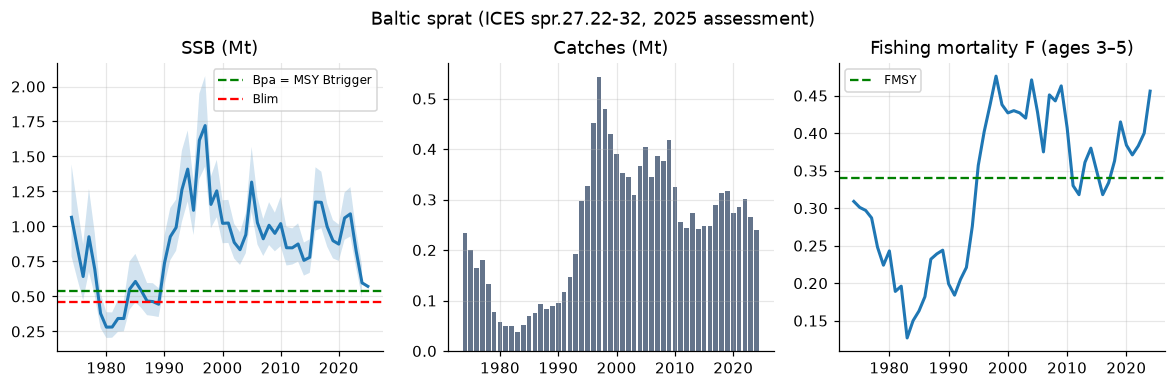

In [65]:
#This cell creates three side-by-side plots using the existing `ices`, `ref`, `plt`, and `pd` variables.

# Plot observed stock, harvest, and fishing mortality against ICES reference points.`  

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
#Creates one figure with three plots in a row. `ax` holds the three axes; `figsize` sets the figure size.

ax[0].fill_between(ices.Year, ices.Low_SSB/1e6, ices.High_SSB/1e6, alpha=.2)
#Shades the range between ICES’s lower and upper SSB estimates. Dividing by `1e6` converts tonnes to million tonnes (Mt); `alpha` controls transparency.

ax[0].plot(ices.Year, ices.x, lw=2); ax[0].set_title("SSB (Mt)")
#Plots the estimated SSB (`ices.x`) by year, with a line width of 2, and titles the first plot.

ax[0].axhline(ref["Bpa"]/1e6, ls="--", c="g", label="Bpa = MSY Btrigger"); ax[0].axhline(ref["Blim"]/1e6, ls="--", c="r", label="Blim"); ax[0].legend(fontsize=8)
#Adds horizontal lines for the Bpa/MSY Btrigger and Blim biomass reference points. Both are converted from tonnes to Mt. The lines are dashed and colored green and red; `legend()` displays their labels.

ax[1].bar(ices.Year, ices.q, color="#64748b"); ax[1].set_title("Catches (Mt)")
#Draws annual catches as bars. `ices.q` is catch in Mt, and the second plot is titled “Catches (Mt).”

ax[2].plot(ices.Year, ices.F, lw=2); ax[2].axhline(ref["FMSY"], ls="--", c="g", label="FMSY"); ax[2].set_title("Fishing mortality F (ages 3–5)"); ax[2].legend(fontsize=8)
#Plots fishing mortality (`F`) by year, adds a dashed line at the ICES FMSY reference value, titles the third plot, and shows its legend.

plt.suptitle("Baltic sprat (ICES spr.27.22-32, 2025 assessment)", y=1.02); plt.show()
#Adds a title above all three plots and displays the figure. The `y` value positions the title slightly above the plots.

### 2b. Windmills: the Polish offshore wind pipeline
Two sources, which do not fully agree — a typical data-integration situation:
* **National reporting** (gramwzielone.pl, 26 Aug 2026): projects under construction, auction winners and planned projects, with first-power years.
* **EMODnet Human Activities** WFS layer `emodnet:windfarms` (live, or snapshot of 26 Oct 2026). For Poland EMODnet holds **points only** (no farm polygons), and several statuses and years lag the national news.

In [66]:
def load_emodnet_windfarms(live=LIVE):
    # Convert WFS point geometry into explicit lon/lat columns used by the map.
    if live:
        try:
            url = "https://ows.emodnet-humanactivities.eu/wfs"
            prm = {"service": "WFS", "version": "2.0.0", "request": "GetFeature", "typeNames": "emodnet:windfarms",
                   "outputFormat": "application/json", "srsName": "EPSG:4326", "CQL_FILTER": "country='Poland'"}
            fc = requests.get(url, params=prm, timeout=30).json()
            df = pd.DataFrame([{**f["properties"], "lon": f["geometry"]["coordinates"][0],
                                "lat": f["geometry"]["coordinates"][1]} for f in fc["features"]])
            print("EMODnet: live WFS,", len(df), "Polish wind farms")
            fields = ["name", "status", "power_mw", "n_turbines", "year", "dist_coast_m", "updateyear", "lon", "lat"]
            return df.reindex(columns=fields)
        except Exception as e:
            print("EMODnet live call failed -> bundled snapshot.", type(e).__name__, e)
    df = pd.read_csv(DATA / "emodnet_windfarms_poland_2026-10-26.csv")
    print("EMODnet: bundled snapshot (26 Oct 2026),", len(df), "farms")
    fields = ["name", "status", "power_mw", "n_turbines", "year", "dist_coast_m", "updateyear", "lon", "lat"]
    return df.reindex(columns=fields)

# EMODnet farm points support the location map; the national pipeline drives Iw,t below.
emod = load_emodnet_windfarms()
national = pd.read_csv(DATA / "polish_offshore_wind_pipeline.csv")
print(f"EMODnet total listed: {emod.power_mw.sum()/1000:.1f} GW  |  national pipeline: {national.capacity_mw.sum()/1000:.1f} GW")
national[["farm", "capacity_mw", "status_aug2026", "first_power_or_completion_year"]]

EMODnet: live WFS, 26 Polish wind farms
EMODnet total listed: 20.9 GW  |  national pipeline: 13.4 GW


,farm,capacity_mw,status_aug2026,first_power_or_completion_year
0,MFW Baltic Power,1200,construction (first power 10 Jul 2026),2026
1,Baltica 2,1500,construction,2027
2,Baltyk 2 + Baltyk 3,1440,construction,2028
3,BC-Wind,390,construction,2028
4,Baltica 3,1000,planned,2030
5,MFW Baltyk 1,1560,planned (Dec 2025 auction),2032
6,Baltica 9+,1300,planned (Dec 2025 auction),2032
7,Baltic East,900,planned (Dec 2025 auction),2032
8,Baltic West,4100,planned (surveys),2035


### Harmonize and link the two wind datasets as GeoJSON-LD

The next cell translates both inputs to the EMODnet windfarm property names (`power_mw`, `status`, `year`, `updateyear`, `n_turbines`, `dist_coast`, and related fields). It adds generic extension properties for information the base block does not represent, such as developer, status reporting date, year meaning, and provenance. Original source column labels are not copied into the output. The Polish extension block is documented at `_sources/emodnet-compliant-windfarm-pl/`.

National pipeline rows have no coordinates, so their geometry is left `null`; no location is invented. Candidate comparisons use harmonized names and properties, with coordinates used only when both records have them. A candidate is evidence for review, not an identity assertion.


In [67]:
# Translate both sources into the EMODnet windfarm vocabulary plus generic extension terms.
# Source column labels are used only on the input side; exported records use target-model names.
import re, unicodedata
from difflib import SequenceMatcher
from math import radians, sin, cos, asin, sqrt

GJ = "https://purl.org/geojson/vocab#"
EM = "https://w3id.org/ogc/hosted/seadots/emodnet-compliant-windfarm#"
SES = "https://w3id.org/ogc/hosted/seadots/emodnet-compliant-windfarm-pl#"
CONTEXT = {
    "@version": 1.1, "geojson": GJ, "em": EM, "ses": SES, "schema": "https://schema.org/",
    "dcterms": "http://purl.org/dc/terms/", "type": "@type", "id": "@id",
    "FeatureCollection": "geojson:FeatureCollection", "Feature": "geojson:Feature",
    "features": {"@id": "geojson:features", "@container": "@set"},
    "geometry": "geojson:geometry", "properties": "geojson:properties",
    "country": {"@id": "schema:addressCountry", "@type": "@vocab"}, "Poland": "http://publications.europa.eu/resource/authority/country/POL",
    "n_turbines": "em:nTurbines", "power_mw": "em:powerMW",
    "status": {"@id": "https://w3id.org/ogc/hosted/seadots/emodnet/", "@type": "@vocab"},
    "type_inst": "schema:additionalType", "updateyear": "em:updateYear", "year": "em:year",
    "dist_coast": "em:distanceToCoast", "notes": "dcterms:description",
    "name": "schema:name", "developer": "schema:creator",
    "status_detail": "ses:statusDetail", "status_as_of": "ses:statusAsOf",
    "year_semantics": "ses:yearSemantics", "year_is_assumed": "ses:yearIsAssumed",
    "source_dataset": "ses:sourceDataset", "source_reference": {"@id": "ses:sourceReference", "@type": "@id"},
    "source_record_id": "ses:sourceRecordId", "source_snapshot_date": "ses:sourceSnapshotDate"
}
NATIONAL_URL = "https://www.gramwzielone.pl/?p=20373718"
EMODNET_URL = "https://ows.emodnet-humanactivities.eu/wfs"

# Convert pandas/numpy values into JSON-safe values; missing values become null.
def clean_value(value):
    if pd.isna(value): return None
    if isinstance(value, (np.integer,)): return int(value)
    if isinstance(value, (np.floating,)): return float(value)
    return value.item() if isinstance(value, np.generic) else value

def generic_status(value):
    if pd.isna(value): return None
    return str(value).split("(")[0].strip().title()

# Harmonize national project rows to the base EMODnet names and extension fields.
national_common = pd.DataFrame(index=national.index)
national_common["name"] = national["farm"]
national_common["power_mw"] = national["capacity_mw"]
national_common["status"] = national["status_aug2026"].map(generic_status)
national_common["status_detail"] = national["status_aug2026"]
national_common["status_as_of"] = "2026-08-26"
national_common["updateyear"] = "2026"
national_common["year"] = national["first_power_or_completion_year"].map(lambda v: None if pd.isna(v) else str(int(v)))
national_common["year_semantics"] = "planned first-power or completion year"
national_common["year_is_assumed"] = national["source"].astype(str).str.contains("assum", case=False, na=False)
national_common["country"] = "Poland"
national_common["n_turbines"] = None
national_common["type_inst"] = None
national_common["dist_coast"] = None
national_common["notes"] = national["source"].map(clean_value)
national_common["developer"] = national["developer"].map(clean_value)
national_common["source_dataset"] = "Polish national offshore wind project pipeline"
national_common["source_reference"] = NATIONAL_URL
national_common["source_snapshot_date"] = "2026-08-26"
national_common["source_record_id"] = [f"national-{i+1}" for i in range(len(national))]

# Harmonize EMODnet properties; distance remains in the source's metres.
emodnet_common = pd.DataFrame(index=emod.index)
for target, source in [("name", "name"), ("power_mw", "power_mw"), ("status", "status"),
                       ("n_turbines", "n_turbines"), ("year", "year"), ("updateyear", "updateyear")]:
    emodnet_common[target] = emod[source].map(clean_value)
emodnet_common["status"] = emodnet_common["status"].map(generic_status)
emodnet_common["status_detail"] = emod["status"].map(clean_value)
emodnet_common["status_as_of"] = None
emodnet_common["year"] = emodnet_common["year"].map(lambda v: None if v is None else str(v))
emodnet_common["updateyear"] = emodnet_common["updateyear"].map(lambda v: None if v is None else str(v))
emodnet_common["year_semantics"] = "year reported by EMODnet"
emodnet_common["year_is_assumed"] = False
emodnet_common["country"] = "Poland"
emodnet_common["type_inst"] = None
emodnet_common["dist_coast"] = emod["dist_coast_m"].map(clean_value)
emodnet_common["notes"] = None
emodnet_common["developer"] = None
emodnet_common["source_dataset"] = "EMODnet Human Activities windfarms"
emodnet_common["source_reference"] = EMODNET_URL
emodnet_common["source_snapshot_date"] = "2026-10-26"
emodnet_common["source_record_id"] = [f"emodnet-{i+1}" for i in range(len(emod))]

BASE_PROPERTIES = ["country", "n_turbines", "power_mw", "status", "type_inst", "updateyear", "year", "dist_coast", "notes"]
EXT_PROPERTIES = ["name", "developer", "status_detail", "status_as_of", "year_semantics", "year_is_assumed", "source_dataset", "source_reference", "source_snapshot_date", "source_record_id"]
def make_feature_collection(df, id_prefix, coords=None):
    features = []
    for index, row in df.reset_index(drop=True).iterrows():
        name = str(row["name"])
        slug = re.sub(r"[^a-z0-9]+", "-", name.lower()).strip("-")
        record_id = f"urn:baltic-ses:{id_prefix}:{index + 1}:{slug}"
        props = {k: clean_value(row[k]) for k in BASE_PROPERTIES + EXT_PROPERTIES}
        geometry = None
        if coords and pd.notna(emod.iloc[index][coords[0]]) and pd.notna(emod.iloc[index][coords[1]]):
            geometry = {"type": "Point", "coordinates": [float(emod.iloc[index][coords[0]]), float(emod.iloc[index][coords[1]])]}
        features.append({"type": "Feature", "id": record_id, "geometry": geometry, "properties": props})
    return {"@context": CONTEXT, "type": "FeatureCollection", "id": f"urn:baltic-ses:dataset:{id_prefix}", "features": features}

national_ld = make_feature_collection(national_common, "national")
emodnet_ld = make_feature_collection(emodnet_common, "emodnet", coords=("lon", "lat"))

def name_tokens(value):
    value = unicodedata.normalize("NFKD", str(value)).encode("ascii", "ignore").decode().lower()
    value = re.sub(r"\bphase\s*\d+\b", " ", value)
    value = re.sub(r"\biii\b", "3", value); value = re.sub(r"\bii\b", "2", value); value = re.sub(r"\bi\b", "1", value)
    value = re.sub(r"\b(mfw|offshore|wind|farm|project)\b", " ", value)
    return re.findall(r"[a-z0-9]+", value)
def name_similarity(a, b):
    ta, tb = set(name_tokens(a)), set(name_tokens(b))
    if not ta or not tb: return 0.0
    overlap = len(ta & tb) / len(ta | tb)
    ratio = SequenceMatcher(None, " ".join(sorted(ta)), " ".join(sorted(tb))).ratio()
    return max(overlap, ratio if overlap >= 0.5 else 0.0)
def distance_km(a, b):
    # Compare Point geometries only, and only when both records provide them.
    ga, gb = a.get("geometry"), b.get("geometry")
    if not ga or not gb or ga.get("type") != "Point" or gb.get("type") != "Point": return None
    lon1, lat1 = ga["coordinates"]
    lon2, lat2 = gb["coordinates"]
    lon1, lat1, lon2, lat2 = map(radians, [float(lon1), float(lat1), float(lon2), float(lat2)])
    h = sin((lat2-lat1)/2)**2 + cos(lat1)*cos(lat2)*sin((lon2-lon1)/2)**2
    return 6371 * 2 * asin(sqrt(h))
def compare_properties(a, b):
    pa, pb = a["properties"], b["properties"]
    ca, cb = pa["power_mw"], pb["power_mw"]
    cap_sim = None if ca is None or cb is None else max(0.0, 1-abs(ca-cb)/max(ca,cb,1))
    status_match = None if not pa["status"] or not pb["status"] else pa["status"] == pb["status"]
    ya, yb = pa["year"], pb["year"]
    year_match = None if not ya or not yb else ya == yb
    vals = [x for x in (cap_sim, None if status_match is None else float(status_match), None if year_match is None else float(year_match)) if x is not None]
    return cap_sim, status_match, year_match, (sum(vals)/len(vals) if vals else None)

# Candidate links are evidence for review, not assertions that records are identical.
candidates = []
for nf in national_ld["features"]:
    for ef in emodnet_ld["features"]:
        np_, ep = nf["properties"], ef["properties"]
        name_score = name_similarity(np_["name"], ep["name"])
        dist = distance_km(nf, ef)
        if name_score < .5 and not (dist is not None and dist <= 20): continue
        cap_sim, status_match, year_match, prop_score = compare_properties(nf, ef)
        delta = None if np_["power_mw"] is None or ep["power_mw"] is None else round(np_["power_mw"]-ep["power_mw"], 1)
        rank = .65*name_score + .35*(prop_score if prop_score is not None else 0)
        method = "name + location" if dist is not None and name_score >= .5 else ("location proximity" if dist is not None else "name similarity")
        candidates.append({"national_id":nf["id"], "emodnet_id":ef["id"], "national_name":np_["name"], "emodnet_name":ep["name"],
            "national_power_mw":np_["power_mw"], "emodnet_power_mw":ep["power_mw"], "capacity_delta_mw":delta,
            "capacity_similarity":None if cap_sim is None else round(cap_sim,3), "national_status":np_["status"], "emodnet_status":ep["status"],
            "status_match":status_match, "national_updateyear":np_["updateyear"], "emodnet_updateyear":ep["updateyear"],
            "national_status_as_of":np_["status_as_of"], "emodnet_status_as_of":ep["status_as_of"],
            "national_year":np_["year"], "emodnet_year":ep["year"], "year_match":year_match, "name_score":round(name_score,3),
            "property_score":None if prop_score is None else round(prop_score,3), "candidate_rank_score":round(rank,3),
            "distance_km":None if dist is None else round(dist,2), "match_method":method})
candidates.sort(key=lambda m:m["candidate_rank_score"], reverse=True)
match_graph = {"@context": CONTEXT, "@graph": [{"@id":f"urn:baltic-ses:match-candidate:{i+1}", "@type":"ses:MatchCandidate",
    "source_record":m["national_id"], "target_record":m["emodnet_id"], "match_method":m["match_method"], "name_score":m["name_score"],
    "property_score":m["property_score"], "candidate_rank_score":m["candidate_rank_score"], "capacity_similarity":m["capacity_similarity"],
    "capacity_delta_mw":m["capacity_delta_mw"], "status_match":m["status_match"], "year_match":m["year_match"], "distance_km":m["distance_km"]}
    for i,m in enumerate(candidates)]}
(DATA / "polish_wind_pipeline.geojsonld").write_text(json.dumps(national_ld, ensure_ascii=False, indent=2))
(DATA / "emodnet_windfarms.geojsonld").write_text(json.dumps(emodnet_ld, ensure_ascii=False, indent=2))
(DATA / "windfarm_match_candidates.jsonld").write_text(json.dumps(match_graph, ensure_ascii=False, indent=2))
print(f"Wrote {len(national_ld['features'])} harmonized national and {len(emodnet_ld['features'])} EMODnet features.")
print("Candidate links compare harmonized name, power, status, year, report date and location; review before treating as the same project.")
pd.DataFrame(candidates)[["national_name","emodnet_name","national_power_mw","emodnet_power_mw","capacity_delta_mw","national_status","emodnet_status","national_updateyear","emodnet_updateyear","national_status_as_of","emodnet_status_as_of","national_year","emodnet_year","name_score","property_score","candidate_rank_score","distance_km"]]


Wrote 9 harmonized national and 26 EMODnet features.
Candidate links compare harmonized name, power, status, year, report date and location; review before treating as the same project.


,national_name,emodnet_name,national_power_mw,emodnet_power_mw,capacity_delta_mw,national_status,emodnet_status,national_updateyear,emodnet_updateyear,national_status_as_of,emodnet_status_as_of,national_year,emodnet_year,name_score,property_score,candidate_rank_score,distance_km
0,Baltica 3,Baltica 3,1000,1045.5,-45.5,Planned,Planned,2026,2026,2026-08-26,None,2030,2030,1.000,0.985,0.995,None
1,MFW Baltic Power,Baltic Power,1200,1140.0,60.0,Construction,Construction,2026,2026,2026-08-26,None,2026,2026,1.000,0.983,0.994,None
2,Baltica 2,Baltica 2,1500,1498.0,2.0,Construction,Planned,2026,2026,2026-08-26,None,2027,2027,1.000,0.666,0.883,None
3,Baltic East,Baltic East,900,966.0,-66.0,Planned,Planned,2026,2026,2026-08-26,None,2032,nan,1.000,0.644,0.875,None
4,Baltica 9+,Baltica 9,1300,975.0,325.0,Planned,Planned,2026,2026,2026-08-26,None,2032,nan,1.000,0.583,0.854,None
5,MFW Baltyk 1,Baltyk I Phase 1,1560,1140.0,420.0,Planned,Planned,2026,2026,2026-08-26,None,2032,2028,1.000,0.577,0.852,None
6,MFW Baltyk 1,Baltyk I Phase 2,1560,420.0,1140.0,Planned,Planned,2026,2026,2026-08-26,None,2032,2028,1.000,0.423,0.798,None
7,Baltyk 2 + Baltyk 3,Baltyk II,1440,720.0,720.0,Construction,Planned,2026,2026,2026-08-26,None,2028,2028,0.889,0.500,0.753,None
8,Baltyk 2 + Baltyk 3,Baltyk III,1440,720.0,720.0,Construction,Planned,2026,2026,2026-08-26,None,2028,2028,0.889,0.500,0.753,None
9,Baltica 2,Baltica 2+,1500,210.0,1290.0,Construction,Planned,2026,2024,2026-08-26,None,2027,nan,1.000,0.047,0.666,None


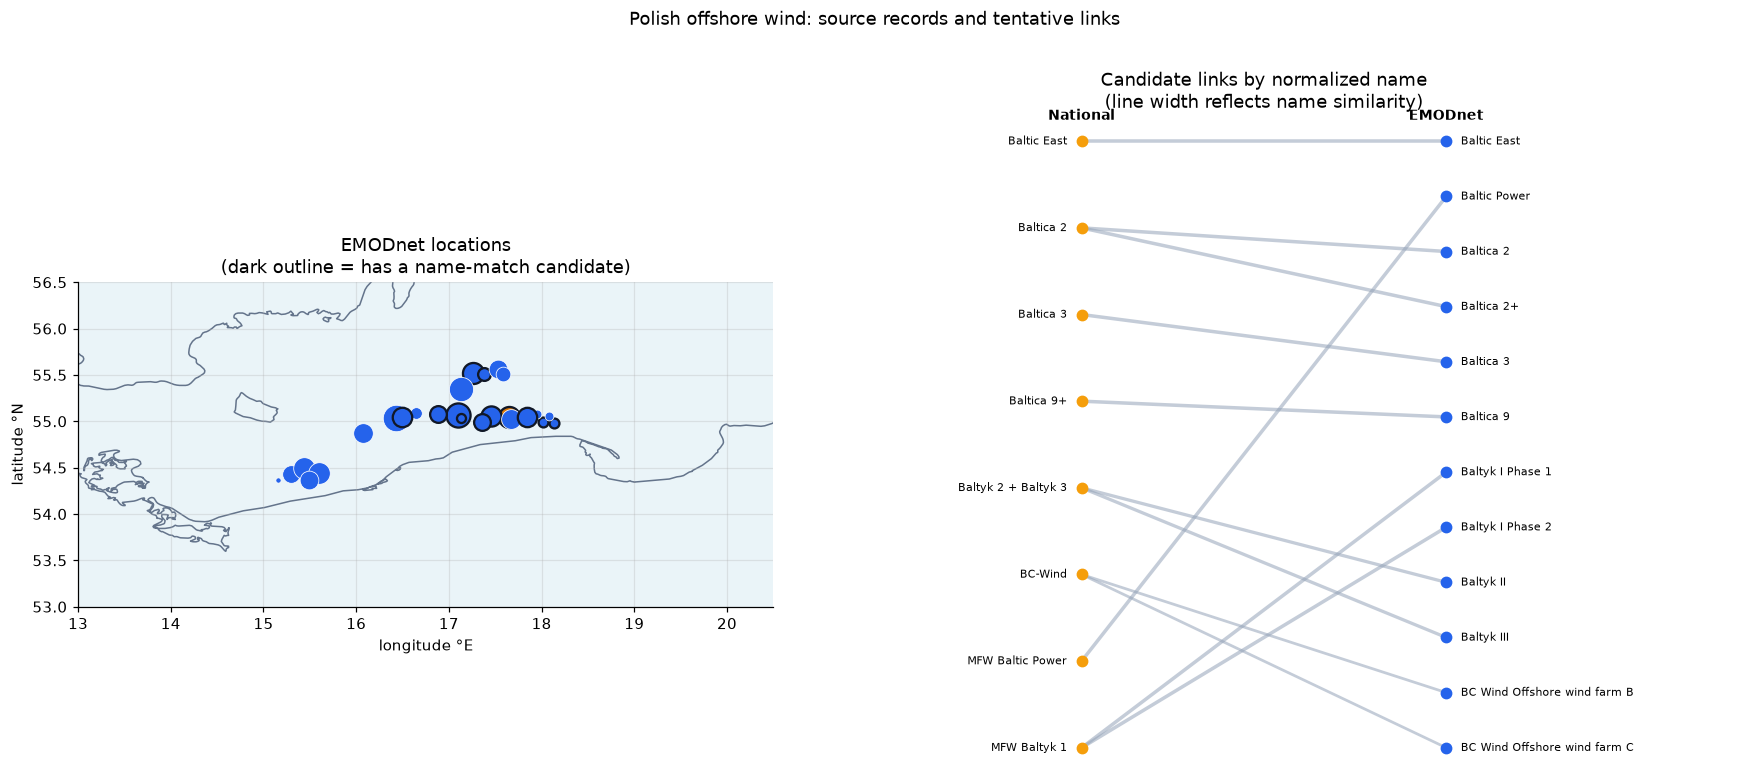

In [68]:
# Visualize the GeoJSON-LD locations and the candidate links between source records.
# National pipeline rows have no coordinates, so the map shows EMODnet points while
# the adjacent bipartite graph shows name-based candidate links for manual review.
coast_features = json.loads((DATA / "ne_10m_coastline_PL_Baltic.geojson").read_text())["features"]
linked_emodnet_ids = {m["emodnet_id"] for m in candidates}
linked_national_ids = {m["national_id"] for m in candidates}

fig, (map_ax, graph_ax) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.1, 1.5]})
for feature in coast_features:
    for segment in feature["geometry"]["coordinates"]:
        xy = np.asarray(segment)
        map_ax.plot(xy[:, 0], xy[:, 1], color="#64748b", lw=1, zorder=1)
map_ax.set_facecolor("#eaf4f8")
status_color = {"Construction": "#d97706", "Production": "#16a34a"}
for feature in emodnet_ld["features"]:
    geom, props = feature["geometry"], feature["properties"]
    if not geom or geom["type"] != "Point":
        continue
    lon, lat = geom["coordinates"]
    is_linked = feature["id"] in linked_emodnet_ids
    map_ax.scatter(lon, lat, s=max(float(props.get("power_mw") or 0) / 6, 12),
                   color=status_color.get(props.get("status"), "#2563eb"),
                   edgecolor="#111827" if is_linked else "white",
                   linewidth=1.5 if is_linked else 0.5, zorder=3)
map_ax.set(xlim=(13, 20.5), ylim=(53, 56.5), xlabel="longitude °E", ylabel="latitude °N",
           title="EMODnet locations\n(dark outline = has a name-match candidate)")
map_ax.set_aspect("equal", adjustable="box")

# Draw a bipartite graph: national records on the left, EMODnet records on the right.
national_by_id = {f["id"]: f["properties"] for f in national_ld["features"]}
emodnet_by_id = {f["id"]: f["properties"] for f in emodnet_ld["features"]}
n_ids = sorted(linked_national_ids, key=lambda i: national_by_id[i]["name"].lower())
e_ids = sorted(linked_emodnet_ids, key=lambda i: emodnet_by_id[i]["name"].lower())
n_y = {key: y for key, y in zip(n_ids, np.linspace(1, 0, max(len(n_ids), 1)))}
e_y = {key: y for key, y in zip(e_ids, np.linspace(1, 0, max(len(e_ids), 1)))}
for match in candidates:
    graph_ax.plot([0, 1], [n_y[match["national_id"]], e_y[match["emodnet_id"]]],
                  color="#94a3b8", alpha=0.55, lw=0.8 + 1.5 * match["name_score"], zorder=1)
graph_ax.scatter([0] * len(n_ids), [n_y[i] for i in n_ids], s=45, color="#f59e0b", zorder=2)
graph_ax.scatter([1] * len(e_ids), [e_y[i] for i in e_ids], s=45, color="#2563eb", zorder=2)
for i in n_ids:
    graph_ax.text(-0.04, n_y[i], national_by_id[i]["name"], ha="right", va="center", fontsize=7)
for i in e_ids:
    graph_ax.text(1.04, e_y[i], emodnet_by_id[i]["name"], ha="left", va="center", fontsize=7)
graph_ax.set(xlim=(-0.8, 1.8), ylim=(-0.04, 1.04), title="Candidate links by normalized name\n(line width reflects name similarity)")
graph_ax.text(0, 1.03, "National", ha="center", va="bottom", fontsize=9, weight="bold")
graph_ax.text(1, 1.03, "EMODnet", ha="center", va="bottom", fontsize=9, weight="bold")
graph_ax.axis("off")
fig.suptitle("Polish offshore wind: source records and tentative links", y=1.01)
plt.tight_layout(); plt.show()


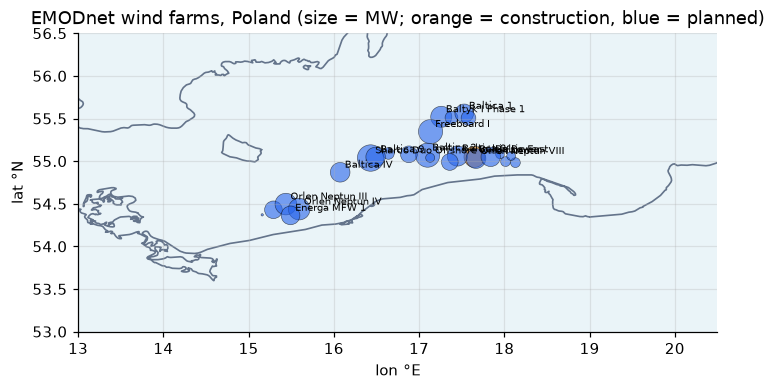

In [69]:
# Draw the bundled Natural Earth coastline first, then overlay EMODnet farm points.
fig, ax = plt.subplots(figsize=(7.5, 4))
coast = json.loads((DATA / "ne_10m_coastline_PL_Baltic.geojson").read_text())
for feature in coast["features"]:
    for segment in feature["geometry"]["coordinates"]:
        xy = np.asarray(segment)
        ax.plot(xy[:, 0], xy[:, 1], color="#64748b", lw=1.1, zorder=1)
ax.set_facecolor("#eaf4f8")
c = emod.status.map({"Construction": "#d97706", "Production": "#16a34a"}).fillna("#2563eb")
ax.scatter(emod.lon, emod.lat, s=emod.power_mw / 6, c=c, alpha=.6, edgecolor="k", lw=.4)
for _, r in emod[emod.power_mw >= 900].iterrows():
    ax.annotate(r["name"].replace(" Offshore wind farm 1", ""), (r.lon, r.lat), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
ax.set_xlim(13, 20.5); ax.set_ylim(53, 56.5)
ax.set_xlabel("lon °E"); ax.set_ylabel("lat °N"); ax.set_aspect("equal", adjustable="box")
ax.set_title("EMODnet wind farms, Poland (size = MW; orange = construction, blue = planned)"); plt.show()

### 2c. Prices and costs

In [70]:
# Prices and explicitly labelled assumptions are stored in long form.
econ = pd.read_csv(DATA / "economic_inputs.csv").set_index("parameter")
econ

,value,unit,status,source
parameter,,,,
sprat_first_sale_price_PL_2024,0.40,EUR/kg,data,EUMOFA species profile European sprat (Poland ...
offshore_wind_auction_price_2025,115.00,EUR/MWh,data,WindEurope 19 Dec 2025 (winning bids ~113-117 ...
baltica2_investment,7110.00,EUR million,data,Notes from Poland 31 Jan 2025 (Baltica 2 ~1.5 GW)
baltica2_capacity,1500.00,MW,data,gramwzielone.pl 26 Aug 2026
capacity_factor,0.45,share,assumption,large 14-15 MW turbines in the Polish Baltic; ...
wind_opex,60.00,EUR million per GW per year,assumption,order of magnitude for offshore O&M (60 EUR/kW...
turbine_lifetime,30.00,years,assumption,del = 1/lifetime
fishing_cost_share,0.85,share of revenue at 2024 state,assumption,replace with STECF AER pelagic trawl segment
discount_rate,0.05,per year,assumption,as in Excel model (roi)


## 3. Calibration (10 min)

### 3a. Fit the fish growth function to ICES data (**FIT**)
Rearranging the stock equation gives the *observed surplus production*: $S_t = x_{t+1} - x_t + q_t$. The Excel growth function says $S_t = \alpha x_t - \beta x_t^2$ (with no windmills yet, $w=0$), so α and β follow from a least-squares regression without intercept.

Units: *x* and *q* in **million tonnes SSB / catch**.

alpha = 0.483/yr   beta = 0.211 per Mt·yr   R² = 0.09   (years 1974–2024)
=> carrying capacity K = 2.29 Mt,  B_MSY = 1.15 Mt,  MSY = 0.277 Mt/yr


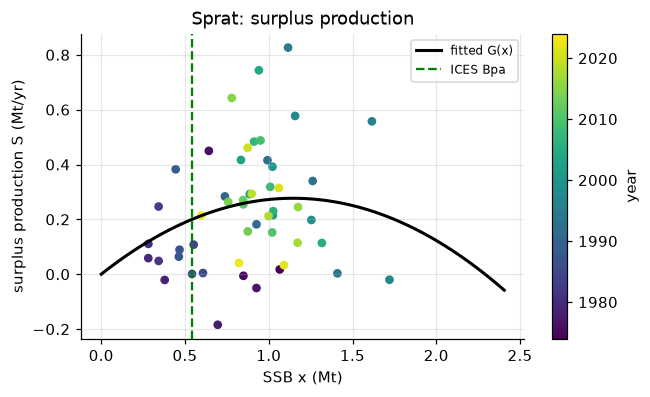

In [47]:
FIT_FROM = 1974                                # try 1990 or 2000 in part 5

# The notebook supplies the loaded ICES data; the model submodule fits α and β.
growth_fit = fit_surplus_production(ices, fit_from=FIT_FROM)
h, fit = growth_fit["history"], growth_fit["fit"]
alpha, beta = growth_fit["alpha"], growth_fit["beta"]
R2, K, Bmsy, MSY = (growth_fit[k] for k in ["R2", "K", "Bmsy", "MSY"])
print(f"alpha = {alpha:.3f}/yr   beta = {beta:.3f} per Mt·yr   R² = {R2:.2f}   (years {int(fit.Year.min())}–{int(fit.Year.max())})")
print(f"=> carrying capacity K = {K:.2f} Mt,  B_MSY = {Bmsy:.2f} Mt,  MSY = {MSY:.3f} Mt/yr")

xs = np.linspace(0, max(K, h.x.max()) * 1.05, 100)
plt.figure(figsize=(6.5, 3.6))
sc = plt.scatter(fit.x, fit.S, c=fit.Year, cmap="viridis", s=22); plt.colorbar(sc, label="year")
plt.plot(xs, alpha * xs - beta * xs**2, "k", lw=2, label="fitted G(x)")
plt.axvline(ref["Bpa"] / 1e6, ls="--", c="g", label="ICES Bpa")
plt.xlabel("SSB x (Mt)"); plt.ylabel("surplus production S (Mt/yr)"); plt.legend(fontsize=8); plt.title("Sprat: surplus production"); plt.show()


> **Discuss.** R² is low: sprat production is driven by recruitment and the environment (temperature, cod predation), not by SSB alone. This is exactly slide 20's warning — a simple *G(x)* is a strong simplification. It is still the best two-parameter description of the data, and it gives a *K* and *B*<sub>MSY</sub> of the right order.

### 3b. Economic parameters in real units
Money is in **EUR million per year**, windmill capacity *w* in **GW**, fish in **Mt**.

In [48]:
# Keep source data and editable assumptions in the notebook; delegate unit conversions and P assembly.
PARAMETER_ASSUMPTIONS = {
    "cof2": 1.1, "cofe2": 1.0, "pu2": 0.9, "pu3": -0.05,
    "eps1": 0.0, "eps2_share": 0.01, "w0": 0.0,
}
P = build_parameter_set(ices, econ, alpha, beta, assumptions=PARAMETER_ASSUMPTIONS)
x24, q24 = ices.loc[ices.Year == 2024, ["x", "q"]].iloc[0]
p_fish, pe, Iwp, dl = P["p"], P["pe"], P["Iwp"], P["dl"]

pd.Series(P).to_frame("value")


,value
alpha,0.483
beta,0.211
p,400.000
cof1,234.273
cof2,1.100
pe,453.330
cofe1,60.000
cofe2,1.000
Iwp,4740.000
dl,0.033


Quick sanity check of what these numbers mean:

In [49]:
print(f"Fishery revenue 2024  : {p_fish*q24:6.0f} EUR m   (catch {q24*1000:.0f} kt at {p_fish:.0f} EUR/t)")
print(f"Wind revenue per GW   : {pe:6.0f} EUR m/yr  (operating cost {P['cofe1']:.0f} EUR m/yr at 1 GW)")
print(f"Capital cost per GW   : {(P['roi']+dl)*Iwp:6.0f} EUR m/yr  (= (r + δ) × {Iwp:.0f} EUR m)")
print(f"PV of one GW's net revenue: {(pe-P['cofe1'])/(P['roi']+dl):6.0f} EUR m   vs investment {Iwp:.0f} EUR m")
print("-> at the auction price a GW of offshore wind roughly breaks even at 5 % — which is what a competitive CfD auction")
print("   should produce. So whether wind adds social value here depends on the interactions and on the public.")

Fishery revenue 2024  :     96 EUR m   (catch 240 kt at 400 EUR/t)
Wind revenue per GW   :    453 EUR m/yr  (operating cost 60 EUR m/yr at 1 GW)
Capital cost per GW   :    395 EUR m/yr  (= (r + δ) × 4740 EUR m)
PV of one GW's net revenue:   4720 EUR m   vs investment 4740 EUR m
-> at the auction price a GW of offshore wind roughly breaks even at 5 % — which is what a competitive CfD auction
   should produce. So whether wind adds social value here depends on the interactions and on the public.


### 3c. The investment path *I<sub>w</sub>(t)* from the national pipeline (**DATA**)
New capacity enters in its first-power/completion year; the year-*t* investment raises *w* from year *t*+1. Two variants: the **contracted** pipeline (construction + Dec 2025 auction winners + Baltica 3, 9.3 GW) and a **full** build-out adding Baltic West (4.1 GW, first power after 2034).

In [50]:
YEARS = np.arange(2025, 2051)                                   # notebook time axis, t = 0..25
# The model submodule converts project MW and first-power years into annual additions in GW.
Iw_contracted = investment_path(national, years=YEARS, exclude_farms=["Baltic West"])
Iw_full = investment_path(national, years=YEARS)
pd.DataFrame({"contracted (GW)": Iw_contracted, "full (GW)": Iw_full}, index=YEARS).query("`full (GW)` > 0")


,contracted (GW),full (GW)
2026,1.20,1.20
2027,1.50,1.50
2028,1.83,1.83
2030,1.00,1.00
2032,3.76,3.76
2035,0.00,4.10


## 4. Baltic scenarios (13 min)

Controls are the two human actions of the model: the **catch** *q* and **wind investment** *I<sub>w</sub>*.

| | Catch rule | Wind | Interactions |
|---|---|---|---|
| **S0** | ICES-style rule: harvest rate *h*<sub>MSY</sub> = α/2, reduced linearly below MSY B<sub>trigger</sub> | none | — |
| **S1** | same rule | contracted 9.3 GW | base: +1 % fishing cost per GW, no growth effect |
| **S2** | same rule | full 13.4 GW | strong: windmills cut growth 5 % at full build-out, +5 % fishing cost per GW |
| **S3** | catch fixed at the 2024 level (240 kt), no rule | contracted 9.3 GW | base |

S0 → S1 isolates the effect of wind; S3 shows what happens without a harvest rule.

All present values include the **terminal value** of the wind fleet in 2050 (see part 5, exercise 5 for the Excel convention without it).

In [51]:
# Configure scenario inputs here; the shared submodule supplies harvest rules and simulation.
ices_rule = ices_harvest_rule(ref)
S3_P = strong_interaction_parameters(P, Iw_full, growth_effect=0.05, cost_share=0.05)
SCEN = {
    "S0": ("No wind, ICES rule",                 P,    ices_rule,        [0.0] * 26),
    "S1": ("Contracted wind, ICES rule",         P,    ices_rule,        Iw_contracted),
    "S2": ("Full wind, rule, strong links",      S3_P, ices_rule,        Iw_full),
    "S3": ("Contracted wind, fixed 2024 catch",  P,    fixed_catch(q24), Iw_contracted),
}
runs, PV = run_scenarios(SCEN, start_year=2025)
PV.columns = ["Fishery", "Windmills", "Public", "Total"]
PV.index = [f"{k} {SCEN[k][0]}" for k in PV.index]
PV.round(0)


,Fishery,Windmills,Public,Total
"S0 No wind, ICES rule",629.0,0.0,1323.0,1952.0
"S1 Contracted wind, ICES rule",594.0,-118.0,1219.0,1695.0
"S2 Full wind, rule, strong links",371.0,-152.0,1198.0,1417.0
"S3 Contracted wind, fixed 2024 catch",-383.0,-118.0,775.0,274.0


### Evolution of the SES (stocks) and paths of human benefits

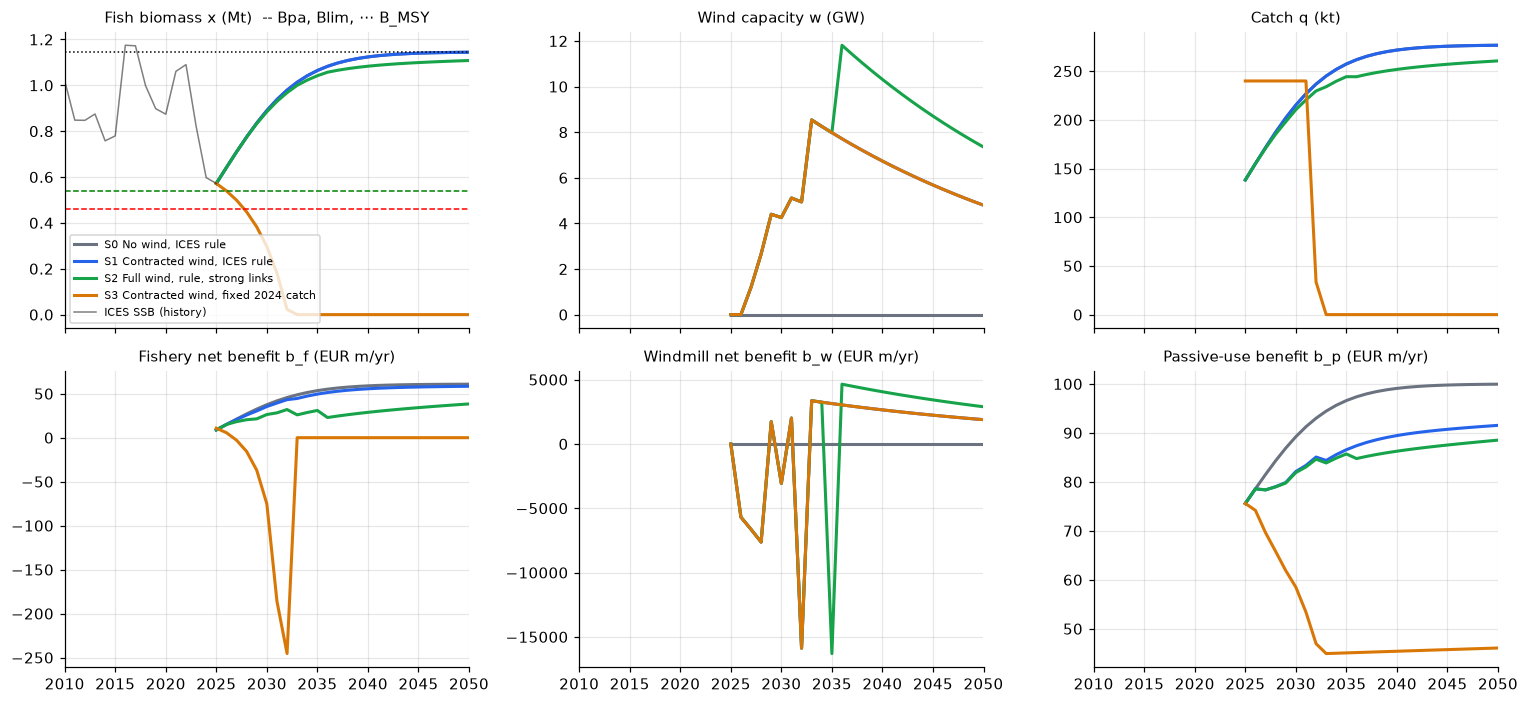

S0 and S1 nearly overlap in the stock panels: with base interactions wind barely touches the stock.


In [52]:
# Compare state variables (x, w, q) and annual benefits (b_f, b_w, b_p).
fig, ax = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True)
for k, d in runs.items():
    kw = dict(c=COL[k], lw=2, label=f"{k} {SCEN[k][0]}")
    ax[0, 0].plot(d.year, d.x, **kw); ax[0, 1].plot(d.year, d.w, **kw); ax[0, 2].plot(d.year, d.q * 1000, **kw)
    ax[1, 0].plot(d.year, d.bf, **kw); ax[1, 1].plot(d.year, d.bw, **kw); ax[1, 2].plot(d.year, d.bp, **kw)
ax[0, 0].axhline(ref["Bpa"] / 1e6, ls="--", c="g", lw=1); ax[0, 0].axhline(ref["Blim"] / 1e6, ls="--", c="r", lw=1)
ax[0, 0].axhline(Bmsy, ls=":", c="k", lw=1)
ax[0, 0].plot(ices.Year[ices.Year >= 2010], ices.x[ices.Year >= 2010], c="k", lw=1, alpha=.5, label="ICES SSB (history)")
for a in ax.flat: a.set_xlim(2010, 2050)
for a, t in zip(ax.flat, ["Fish biomass x (Mt)  -- Bpa, Blim, ··· B_MSY", "Wind capacity w (GW)", "Catch q (kt)",
                          "Fishery net benefit b_f (EUR m/yr)", "Windmill net benefit b_w (EUR m/yr)", "Passive-use benefit b_p (EUR m/yr)"]):
    a.set_title(t, fontsize=10)
ax[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()
print("S0 and S1 nearly overlap in the stock panels: with base interactions wind barely touches the stock.")

> **Read the plots.** Under the ICES-style rule (S0–S2) catches start lower (the stock is near MSY B<sub>trigger</sub>) and the stock rebuilds towards *B*<sub>MSY</sub>. With the catch fixed at the 2024 level (S3) the fitted stock cannot sustain it and collapses within a decade — the fitted model is pessimistic, but the direction matches ICES advice to cut catches. Windmill benefits are negative in the big investment years and positive once the farms run. Compare S0 and S1 for the cost wind imposes on the fishery, and S1 and S2 for how much that depends on the (assumed) interaction strength.

### Present values by sector

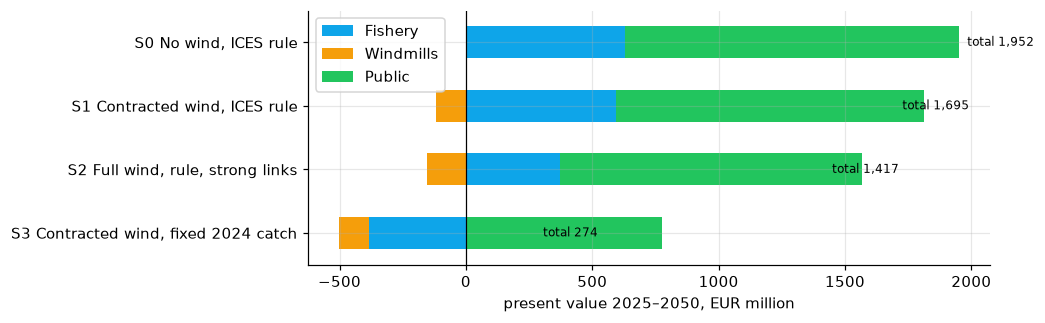

In [53]:
# Stack sector present values to compare scenario totals.
ax = PV[["Fishery", "Windmills", "Public"]].plot.barh(stacked=True, figsize=(8, 3), color=["#0ea5e9", "#f59e0b", "#22c55e"])
for i, v in enumerate(PV.Total):
    ax.text(v, i, f"  total {v:,.0f}", va="center", fontsize=8)
ax.axvline(0, c="k", lw=.8); ax.set_xlabel("present value 2025–2050, EUR million"); ax.invert_yaxis(); plt.show()

### Fisheries Kobe diagram
Left: model paths, biomass relative to *B*<sub>MSY</sub> and harvest rate relative to *h*<sub>MSY</sub> (green = sustainable). Right: the ICES history of the real stock, SSB / MSY B<sub>trigger</sub> against F / F<sub>MSY</sub>.

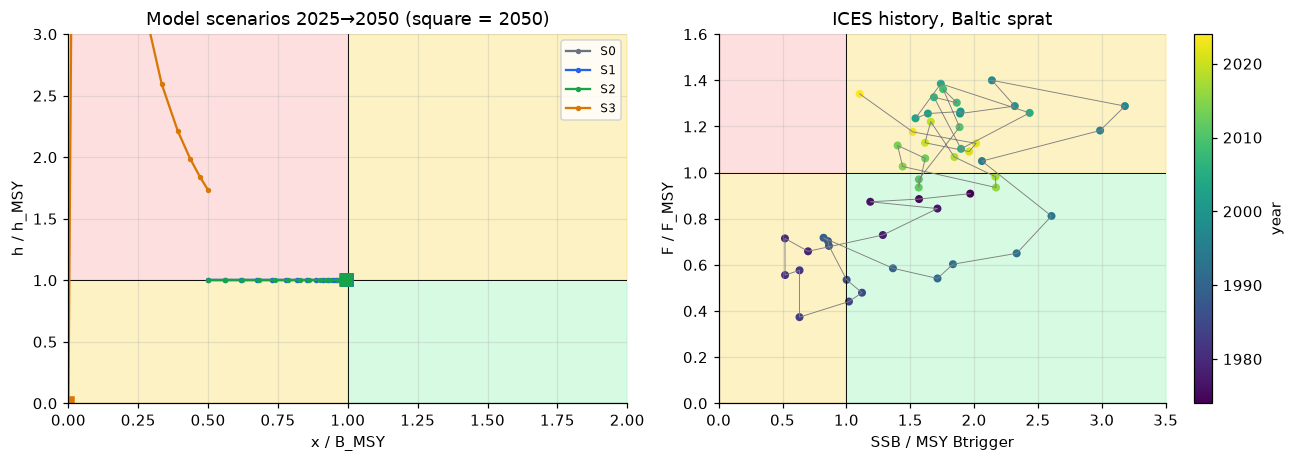

In [54]:
def kobe_bg(a, xmax, ymax):
    a.fill_between([0, 1], 0, 1, color="#fde68a", alpha=.5); a.fill_between([1, xmax], 0, 1, color="#bbf7d0", alpha=.6)
    a.fill_between([0, 1], 1, ymax, color="#fecaca", alpha=.6); a.fill_between([1, xmax], 1, ymax, color="#fde68a", alpha=.5)
    a.set_xlim(0, xmax); a.set_ylim(0, ymax); a.axhline(1, c="k", lw=.6); a.axvline(1, c="k", lw=.6)

# Normalize biomass and harvest pressure by MSY reference points (Kobe diagram).
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
kobe_bg(ax[0], 2, 3)
for k, d in runs.items():
    Pk = SCEN[k][1]
    bmsy = (Pk["alpha"] - Pk["eps1"] * d.w) / (2 * Pk["beta"]); hmsy = (Pk["alpha"] - Pk["eps1"] * d.w) / 2
    bx, hy = d.x / bmsy, (d.q / d.x.clip(lower=1e-9)) / hmsy
    ax[0].plot(bx, hy, "-o", ms=2.5, c=COL[k], label=k); ax[0].plot(bx.iloc[-1], hy.iloc[-1], "s", ms=8, c=COL[k])
ax[0].set_xlabel("x / B_MSY"); ax[0].set_ylabel("h / h_MSY"); ax[0].set_title("Model scenarios 2025→2050 (square = 2050)"); ax[0].legend(fontsize=8)

kobe_bg(ax[1], 3.5, 1.6)
hist = ices.dropna(subset=["F"])
sc = ax[1].scatter(hist.SSB / ref["MSYBtrigger"], hist.F / ref["FMSY"], c=hist.Year, cmap="viridis", s=18)
ax[1].plot(hist.SSB / ref["MSYBtrigger"], hist.F / ref["FMSY"], c="grey", lw=.6)
plt.colorbar(sc, ax=ax[1], label="year"); ax[1].set_xlabel("SSB / MSY Btrigger"); ax[1].set_ylabel("F / F_MSY")
ax[1].set_title("ICES history, Baltic sprat"); plt.tight_layout(); plt.show()

### Initial and final benefits (radar)
2025 (dashed) against 2050 (solid). Each axis is scaled to the largest value across all scenarios and both dates; negative benefits show as zero. Left: S0 without wind; right: the scenario chosen with `RADAR`.

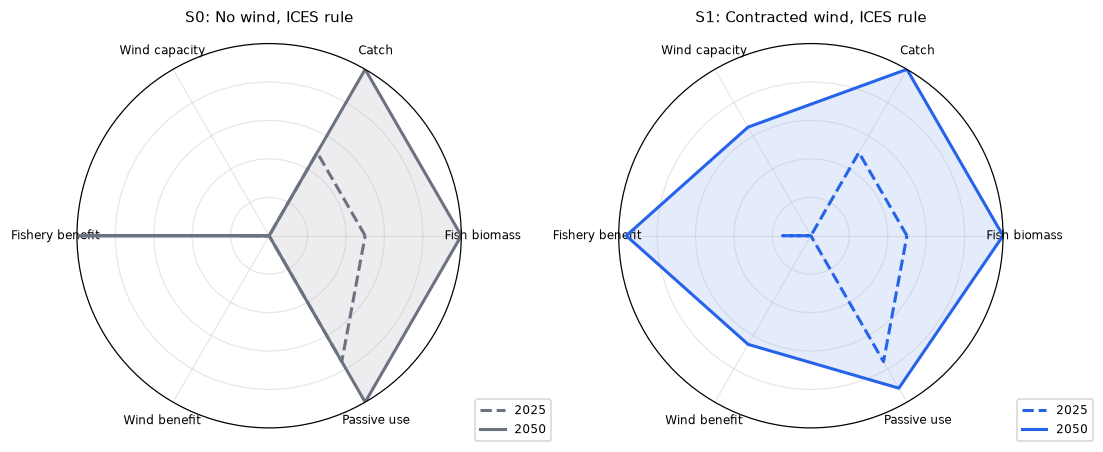

In [55]:
RADAR = "S1"
axes = ["x", "q", "w", "bf", "bw", "bp"]
labels = ["Fish biomass", "Catch", "Wind capacity", "Fishery benefit", "Wind benefit", "Passive use"]
# Use a shared scale across scenarios and years; negative benefits are clipped for display only.
allv = pd.concat([d[axes].iloc[[0, -1]] for d in runs.values()])
scale = allv.abs().max().replace(0, 1)
ang = np.linspace(0, 2 * np.pi, len(axes), endpoint=False).tolist(); ang += ang[:1]

fig = plt.figure(figsize=(10, 4.2))
for i, k in enumerate(["S0", RADAR]):
    a = fig.add_subplot(1, 2, i + 1, polar=True)
    for row, lab, st in [(0, "2025", "--"), (-1, "2050", "-")]:
        v = (runs[k][axes].iloc[row].clip(lower=0) / scale).tolist(); v += v[:1]
        a.plot(ang, v, st, c=COL[k], lw=2, label=lab); a.fill(ang, v, c=COL[k], alpha=.12 if row else 0)
    a.set_xticks(ang[:-1]); a.set_xticklabels(labels, fontsize=8); a.set_yticklabels([]); a.set_ylim(0, 1)
    a.set_title(f"{k}: {SCEN[k][0]}", fontsize=10, pad=14); a.legend(fontsize=8, loc="lower right", bbox_to_anchor=(1.25, -.05))
plt.tight_layout(); plt.show()

### Equilibrium and individual industries
As on the *Individual industries* sheet: what each sector earns in a sustained steady state, holding the other sector fixed.

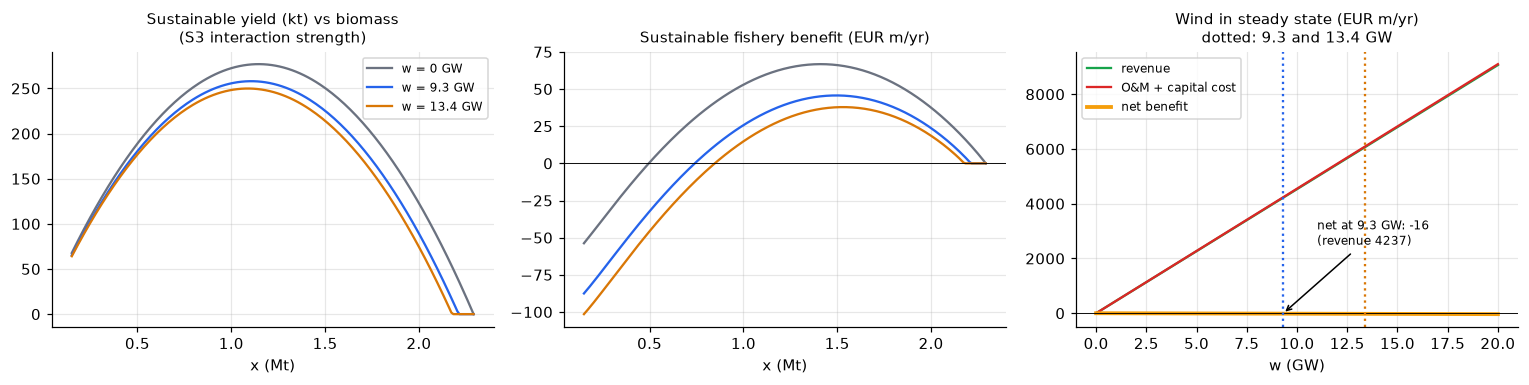

In [56]:
# Hold wind capacity fixed to show sustainable yield and sector returns over stock levels.
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
xs = np.linspace(0.15, K, 200)
for wv, c in [(0, "#6b7280"), (9.3, "#2563eb"), (13.4, "#d97706")]:
    Pw = S3_P                                                     # strong-interaction case, to make the effect visible
    qs, bf = sustainable_fishery_returns(Pw, xs, wv)
    ax[0].plot(xs, qs * 1000, c=c, label=f"w = {wv} GW"); ax[1].plot(xs, bf, c=c, label=f"w = {wv} GW")
ax[0].set_title("Sustainable yield (kt) vs biomass\n(S3 interaction strength)", fontsize=10); ax[0].set_xlabel("x (Mt)"); ax[0].legend(fontsize=8)
ax[1].set_title("Sustainable fishery benefit (EUR m/yr)", fontsize=10); ax[1].set_xlabel("x (Mt)"); ax[1].axhline(0, c="k", lw=.6)
ws = np.linspace(0, 20, 200)
rev, cost, net = wind_steady_state_returns(P, ws)
ax[2].plot(ws, rev, c="#16a34a", label="revenue"); ax[2].plot(ws, cost, c="#dc2626", label="O&M + capital cost")
ax[2].plot(ws, net, c="#f59e0b", lw=2.5, label="net benefit")
ax[2].axhline(0, c="k", lw=.6); ax[2].axvline(9.3, ls=":", c="#2563eb"); ax[2].axvline(13.4, ls=":", c="#d97706")
i93 = np.abs(ws - 9.3).argmin()
ax[2].annotate(f"net at 9.3 GW: {net[i93]:.0f}\n(revenue {rev[i93]:.0f})", (9.3, net[i93]), xytext=(11, 2500), fontsize=8, arrowprops=dict(arrowstyle="->"))
ax[2].set_title("Wind in steady state (EUR m/yr)\ndotted: 9.3 and 13.4 GW", fontsize=10); ax[2].set_xlabel("w (GW)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Your turn (10 min)

Pick one or two and change the marked lines in the cell below. Re-run it and compare with the table in part 4.

1. **Interactions matter?** Set `eps2` to 10 % of `cof1` per GW and `eps1` so that 13.4 GW cuts growth by 10 %. Does wind change the fishery PV much compared with the catch rule?
2. **The public dislikes turbines.** Use the Excel value `pu3 = -1.1`. Does any wind scenario still beat S0 in total?
3. **Productivity regime.** Back in 3a, set `FIT_FROM = 2000` and re-run parts 3–4. How do *K*, *B*<sub>MSY</sub> and the fixed-catch scenarios change?
4. **Discounting.** Compare `roi = 0.02` and `0.08`. Which sector is most sensitive, and why?
5. **The 26-year horizon cuts off wind revenue.** Turbines built in 2032 are paid for but run only 18 years inside the window. Set `TERMINAL_VALUE = False` (the Excel convention) and see what happens to the wind PV. Also try the Excel O&M exponent `cofe2 = 1.5`.
6. **Policy search.** Which constant harvest rate *h* (catch = *h·x*) maximises total PV with the contracted wind pipeline? (grid search at the bottom)

In [57]:
# Change the marked assumptions/rules, rerun, and compare with reference scenario S1.
# ---- edit me -------------------------------------------------------------
P_try = {**P,
         "eps1": 0.0,          # exercise 1
         "eps2": 0.01 * P["cof1"],
         "pu3": -0.05,         # exercise 2: try -1.1
         "roi": 0.05,          # exercise 4
         "cofe2": 1.0}         # exercise 5: Excel used 1.5
TERMINAL_VALUE = True          # exercise 5: False = Excel convention
harvest, invest = ices_rule, Iw_contracted
# ---------------------------------------------------------------------------

d = simulate(P_try, harvest, invest, start_year=2025)
pv = present_values(d, P_try, terminal=TERMINAL_VALUE)
print(pd.DataFrame({"your run": pv.values, "S1 reference": PV.iloc[1].values},
                   index=["Fishery", "Windmills", "Public", "Total"]).round(0))

           your run  S1 reference
Fishery       594.0         594.0
Windmills    -118.0        -118.0
Public       1219.0        1219.0
Total        1695.0        1695.0


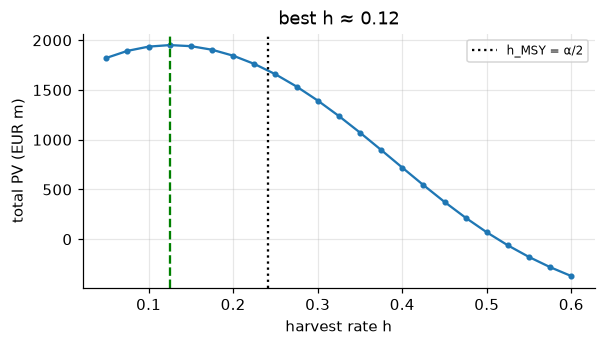

In [58]:
# Search constant harvest rates h; each candidate applies annual attempted catch q = h*x.
# exercise 6: policy search over a constant harvest rate h
hs = np.linspace(0.05, 0.6, 23)
# Score each candidate by discounted total benefits, including terminal wind value.
tot = [present_values(simulate(P, (lambda h: lambda t, x, w, P: h * x)(h), Iw_contracted, start_year=2025), P, terminal=True).B for h in hs]
best = hs[int(np.argmax(tot))]
plt.figure(figsize=(6, 3)); plt.plot(hs, tot, "-o", ms=3); plt.axvline(best, ls="--", c="g")
plt.axvline(P["alpha"] / 2, ls=":", c="k", label="h_MSY = α/2"); plt.legend(fontsize=8)
plt.xlabel("harvest rate h"); plt.ylabel("total PV (EUR m)"); plt.title(f"best h ≈ {best:.2f}"); plt.show()

## 6. Bonus: where does each number come from? (≈ 10 min)

The GeoJSON-LD cell in part 2b linked the *wind-farm records*. This section links the *model parameters*. `data/model_inputs.jsonld` describes every value that enters `P` with standard vocabularies, in the same `urn:baltic-ses:` namespace:

| Question | Annotation | Vocabulary |
|---|---|---|
| Which source, which edition, retrieved when, updated how often? | dataset, version, series, periodicity | DCAT, Dublin Core |
| Is it data, a fit or an assumption, and what was it derived from? | evidence status, derivation chain | SKOS, PROV-O |
| What does the source column actually measure? | property, object of interest, context | I-ADOPT, WoRMS taxon IDs |
| In which unit, and how is it converted to model units? | unit and conversion factor | QUDT |

The cell below then uses only these annotations, not hand-written code, to:

1. list each parameter's lineage;
2. **re-derive every unit conversion** and compare it with `P`;
3. check that sources joined in one calculation describe the same species, and flag joins across different spatial scopes;
4. check whether a **newer edition** of a source exists, and which parameters and scenarios it affects.

In [59]:
# Load the semantic annotations and check them against the parameters P of this run.
import datetime as dt
INJECT_UNIT_ERROR = False      # try True: the price annotation claims EUR per tonne instead of EUR per kg

meta = json.loads((DATA / "model_inputs.jsonld").read_text(encoding="utf-8"))
node = {n["@id"]: n for n in meta["@graph"]}
of_type = lambda t: [n for n in meta["@graph"] if n.get("@type") == t]
params, datasets = of_type("ses:ModelParameter"), {n["@id"]: n for n in of_type("dcat:Dataset")}
label = lambda i: node.get(i, {}).get("label") or node.get(i, {}).get("title") or i
if INJECT_UNIT_ERROR:
    node["urn:baltic-ses:parameter:p"]["sourceQuantity"]["unit"] = "ses:EUR-PER-TONNE"

def as_list(v): return v if isinstance(v, list) else ([] if v is None else [v])

# --- 1. lineage: follow prov:wasDerivedFrom / prov:wasGeneratedBy / prov:used down to datasets ----------
def sources(i, seen=None):
    seen = set() if seen is None else seen
    if i in seen: return set()
    seen.add(i); n = node.get(i, {})
    if n.get("@type") == "dcat:Dataset": return {i}
    nxt = as_list(n.get("derivedFrom")) + as_list(n.get("generatedBy")) + as_list(n.get("used"))
    return set().union(*[sources(j, seen) for j in nxt]) if nxt else set()

# --- 2. units: reduce any QUDT unit to (factor to SI, base dimensions) and convert ---------------------
def reduce_unit(u):
    n = node[u]
    if "factors" not in n: return float(n["multiplier"]), {n["dimension"]: 1}
    f, dims = 1.0, {}
    for part in n["factors"]:
        m, d = reduce_unit(part["of"])
        f *= m ** part["exp"]
        for k, e in d.items(): dims[k] = dims.get(k, 0) + e * part["exp"]
    return f, {k: e for k, e in dims.items() if e}

def resolve(term):
    # 'econ:<parameter>' reads economic_inputs.csv; 'ices:<column>@<year>' reads the ICES table in use.
    kind, ref = term.split(":", 1)
    if kind == "econ": return float(econ.loc[ref, "value"])
    col, year = ref.split("@"); return float(ices.loc[ices.Year == int(year), col].iloc[0])

def source_value(q):
    v = [resolve(t) for t in q["terms"]]
    return {"value": v[0], "product": np.prod(v), "ratio": v[0] / v[-1] if len(v) > 1 else v[0], "inverse": 1 / v[0]}[q["op"]]

rows = []
for prm in params:
    key, used = prm["key"], P.get(prm["key"], globals().get(prm["key"]))
    srcs = sorted(sources(prm["@id"]))
    row = {"parameter": f'{prm["symbol"]} ({key})', "status": node[prm["status"]]["label"],
           "value in P": used if np.isscalar(used) else "series",
           "model unit": label(prm.get("modelUnit")) if prm.get("modelUnit") else "",
           "sources": "; ".join(f'{datasets[s].get("publisher")} {datasets[s].get("version") or datasets[s].get("issued")}' for s in srcs),
           "unit check": ""}
    q = prm.get("sourceQuantity")
    if q:
        f_src, d_src = reduce_unit(q["unit"]); f_mod, d_mod = reduce_unit(prm["modelUnit"])
        if d_src != d_mod:
            row["unit check"] = f"✗ dimensions differ: {d_src} vs {d_mod}"
        else:
            expected = source_value(q) * f_src / f_mod
            ok = abs(expected - used) <= 0.005 * max(abs(used), 1e-12)
            row["unit check"] = (f"✓ {expected:.4g}" if ok else f"✗ annotation gives {expected:.4g}, P has {used:.4g} (×{used/expected:.3g})")
    rows.append(row)
lineage = pd.DataFrame(rows).set_index("parameter")
display(lineage)
print("Note on p_e: the annotation uses the QUDT year (365.25 d = 8766 h) while part 3b used 8760 h,",
      "a 0.07 % convention difference that was invisible in the code.")

# --- 3. joins: same species? same spatial scope? ------------------------------------------------------------
print("\nModel variables vs observed variables:")
for mv in of_type("ses:ModelVariable"):
    match, how = (mv["exactMatch"], "exactMatch") if "exactMatch" in mv else (mv["closeMatch"], "closeMatch")
    print(f'  {mv["symbol"]:>2} {how:<10} {label(match)}' + (f'  ← {mv["note"]}' if how == "closeMatch" else ""))
in_use = {s for prm in params for s in sources(prm["@id"])}
fish_sources = [datasets[d] for d in sorted(in_use) if datasets[d].get("aboutTaxon")]
taxa = {d["aboutTaxon"] for d in fish_sources}
print("\nFish sources joined in calibration:", ", ".join(d["publisher"] for d in fish_sources),
      "→", "same taxon ✓ " + ", ".join(f'{label(t)} ({t})' for t in taxa) if len(taxa) == 1 else f"✗ different taxa {taxa}")
print("Spatial scopes combined in the model:")
used_ds = [datasets[d] for d in in_use]
for scope in sorted({d["spatialScope"] for d in used_ds}):
    print("  -", scope, "←", ", ".join(sorted({d["publisher"] for d in used_ds if d["spatialScope"] == scope})))
print("  ⚠ the stock is assessed for the whole Baltic, the wind farms are in the Polish EEZ: the scale mismatch noted in the wrap-up.")

# --- 4. freshness: is the edition used still the latest one? -----------------------------------------------
today = dt.date.today()
print("\nFreshness of the sources used in this run:")
newer = {}
for d in sorted(in_use, key=lambda i: datasets[i]["publisher"]):
    ds, msg = datasets[d], ""
    if ds.get("inSeries"):
        series = node[ds["inSeries"]]
        members = [m for m in datasets.values() if m.get("inSeries") == ds["inSeries"]]
        if LIVE:
            try:   # ask ICES which assessments of this stock exist now
                for y in (today.year, today.year - 1):
                    hits = [s for s in requests.get(series["liveCheck"].format(year=y), timeout=20).json()
                            if s["StockKeyLabel"] == series["stockKeyLabel"]]
                    if hits:
                        top = max(hits, key=lambda h: int(h["AssessmentYear"]))
                        members.append({"version": str(top["AssessmentYear"]),
                                        "@id": f'live ICES SAG: assessment key {top["AssessmentKey"]}'})
                        break
            except Exception as e:
                print(f"    live series check failed ({type(e).__name__}); using the series members listed in the annotations")
        later = [m for m in members if (m.get("version") or "") > ds["version"]]
        if later:
            newer[d] = max(later, key=lambda m: m["version"])
            msg = f"⚠ newer edition {newer[d]['version']} exists: {newer[d]['@id']}"
    elif ds.get("periodicity") == "freq:annual" and ds.get("version"):
        if int(ds["version"]) < today.year - 1: msg = f"⚠ annual series; {int(ds['version'])+1} edition probably available"
    print(f'  {ds["publisher"]:<26} {ds.get("version") or ds.get("issued"):<11} {msg or "✓ current as far as the annotations know"}')

affected = [prm for prm in params if sources(prm["@id"]) & set(newer)]
if affected:
    print("\nParameters that depend on a superseded edition:",
          ", ".join(f'{p_["symbol"]} ({p_["key"]})' for p_ in affected), "→ and therefore every scenario in part 4.")

,status,value in P,model unit,sources,unit check
parameter,,,,,
α (alpha),FIT,0.483,per year,ICES 2025,
β (beta),FIT,0.211,per million tonnes per year,ICES 2025,
x₀ (x0),DATA,0.572,million tonnes,ICES 2025,✓ 0.5721
p (p),DATA,400.0,million EUR per million tonnes,EUMOFA 2024,✓ 400
c₁ (cof1),ASSUMPTION,234.273,,EUMOFA 2024; ICES 2025,
c₂ (cof2),ASSUMPTION,1.1,dimensionless,,
p_e (pe),ASSUMPTION,453.33,million EUR per GW per year,WindEurope 2025-12-19,✓ 453.6
c_e1 (cofe1),ASSUMPTION,60.0,million EUR per GW per year,,✓ 60
c_e2 (cofe2),ASSUMPTION,1.0,dimensionless,,


Note on p_e: the annotation uses the QUDT year (365.25 d = 8766 h) while part 3b used 8760 h, a 0.07 % convention difference that was invisible in the code.

Model variables vs observed variables:
   x closeMatch Spawning-stock biomass of Baltic sprat  ← closeMatch, not exactMatch: the model's x is a single-stock biomass with logistic growth; it is calibrated on SSB, which excludes juveniles.
   q exactMatch Total catch of Baltic sprat

Fish sources joined in calibration: EUMOFA, ICES → same taxon ✓ Sprattus sprattus (worms:126425)
Spatial scopes combined in the model:
  - ICES subdivisions 22-32 (whole Baltic stock) ← ICES
  - Poland (national first sales) ← EUMOFA
  - Polish EEZ ← Notes from Poland, WindEurope, gramwzielone.pl
  ⚠ the stock is assessed for the whole Baltic, the wind farms are in the Polish EEZ: the scale mismatch noted in the wrap-up.

Freshness of the sources used in this run:
  EUMOFA                     2024        ⚠ annual series; 2025 edition probably available


In [60]:
# What would the newer ICES assessment change? Refit with the same method and compare scenario S1.
d_old = "urn:baltic-ses:dataset:ices-sag-20915"
new = node.get(newer.get(d_old, {}).get("@id", ""), {}) or node["urn:baltic-ses:dataset:ices-sag-22378"]
ices_new = pd.read_csv(DATA / new["localFile"][0]).astype(float)
ices_new["x"], ices_new["q"] = ices_new.SSB / 1e6, ices_new.Catches / 1e6
growth_new = fit_surplus_production(ices_new, fit_from=FIT_FROM)
P_new = update_ices_dependent_parameters(P, ices_new, econ, growth_new["alpha"], growth_new["beta"])
cmp = pd.DataFrame({"assessment 2025 (in use)": {k: P[k] for k in ["x0", "alpha", "beta", "cof1", "pu1"]},
                    f'assessment {new["version"]}': {k: P_new[k] for k in ["x0", "alpha", "beta", "cof1", "pu1"]}})
cmp.loc["B_MSY = α/2β"] = [P["alpha"] / (2 * P["beta"]), P_new["alpha"] / (2 * P_new["beta"])]
cmp.loc["SSB in 2026 (Mt)"] = [np.nan, float(ices_new.loc[ices_new.Year == 2026, "x"].iloc[0])]
for lab, PP in [("assessment 2025 (in use)", P), (f'assessment {new["version"]}', P_new)]:
    pv = present_values(simulate(PP, ices_rule, Iw_contracted, start_year=2025), PP, terminal=True)
    cmp.loc["S1 PV fishery (EUR m)", lab], cmp.loc["S1 PV total (EUR m)", lab] = pv.bf, pv.B
display(cmp.round(3))

# Record this run as PROV: which source editions were used and which parameter values were generated.
run_id = f"urn:baltic-ses:run:{dt.datetime.now(dt.timezone.utc):%Y%m%dT%H%M%SZ}"
run = {"@context": meta["@context"], "@graph": [
    {"@id": run_id, "@type": "prov:Activity", "label": "baltic_ses_exercise.ipynb run",
     "used": sorted(in_use), "note": f"LIVE={LIVE}, FIT_FROM={FIT_FROM}"}] + [
    {"@id": f'{run_id}:{prm["key"]}', "@type": "prov:Entity", "generatedBy": run_id,
     "derivedFrom": [prm["@id"]], "label": f'{prm["key"]} = {P[prm["key"]]:.6g}', "status": prm["status"]}
    for prm in params if np.isscalar(P.get(prm["key"]))]}
(DATA / "model_run_provenance.jsonld").write_text(json.dumps(run, ensure_ascii=False, indent=2))
print("Wrote data/model_run_provenance.jsonld for", run_id)

# Optional: the same question as one SPARQL query over standard RDF (pip install rdflib).
try:
    import rdflib
    g = rdflib.Graph()
    g.parse(DATA / "model_inputs.jsonld", format="json-ld")
    g.parse(DATA / "model_run_provenance.jsonld", format="json-ld")
    q = """PREFIX prov: <http://www.w3.org/ns/prov#>  PREFIX dcat: <http://www.w3.org/ns/dcat#>
           PREFIX ses: <urn:baltic-ses:vocab:>
           SELECT DISTINCT ?key ?used ?newerVersion WHERE {
             ?p ses:parameterKey ?key ; (prov:wasDerivedFrom|prov:wasGeneratedBy|prov:used)+ ?ds .
             ?ds dcat:inSeries ?s ; dcat:version ?used .
             ?other dcat:inSeries ?s ; dcat:version ?newerVersion .
             FILTER(STR(?newerVersion) > STR(?used)) } ORDER BY ?key"""
    print(f"\nrdflib: {len(g)} triples. SPARQL — parameters built on a superseded edition:")
    for r in g.query(q): print(f"  {r.key}: uses {r.used}, newer {r.newerVersion}")
except ImportError:
    print("\n(rdflib not installed: skip the SPARQL view; the checks above do not need it)")

,assessment 2025 (in use),assessment 2026
x0,0.572,0.621
alpha,0.483,0.525
beta,0.211,0.244
cof1,234.273,248.991
pu1,50.304,51.796
B_MSY = α/2β,1.146,1.077
SSB in 2026 (Mt),NaN,1.123
S1 PV fishery (EUR m),594.246,569.859
S1 PV total (EUR m),1695.291,1700.666


Wrote data/model_run_provenance.jsonld for urn:baltic-ses:run:20261027T215117Z

rdflib: 561 triples. SPARQL — parameters built on a superseded edition:
  alpha: uses 2025, newer 2026
  beta: uses 2025, newer 2026
  cof1: uses 2025, newer 2026
  eps2: uses 2025, newer 2026
  pu1: uses 2025, newer 2026
  x0: uses 2025, newer 2026


> **Read the result.**
> * **Unit checks.** Every conversion in part 3b is reproduced from the annotations alone. Set `INJECT_UNIT_ERROR = True` to see how a wrong unit, EUR per tonne instead of per kg, shows up immediately as a ×1000 error. That is the kind of error found in HELCOM (Baltic I, ×10) and EMODnet (Bockstigen, ×1000).
> * **Joins and scope.** The species join is checked through WoRMS IDs, not trusted from names, and the `closeMatch` between *x* and SSB makes a model simplification explicit.
> * **Freshness.** ICES has published the **2026** assessment (key 22378). Refitting with it raises x₀ by about 9 % (0.57 → 0.62 Mt), lowers *B*<sub>MSY</sub> from 1.15 to 1.08 Mt, and cuts the S1 fishery PV by about 4 %; the total barely moves. The bigger news is the 2026 SSB of 1.12 Mt after a strong 2025 year class, already above *B*<sub>MSY</sub>, which scenarios starting in 2025 cannot see. The lineage shows exactly which six parameters, and so which results, to recompute.
> * **Why use the vocabularies at all.** The same file can be read by other SEADOTs tools, catalogues (DCAT) and validators (SHACL) without this notebook. To switch the training to the 2026 data, change the `@id` in the x₀ / fit annotations and the ICES file names in part 2a.

## Wrap-up: what was real and what was assumed

| Element | Status | Source / how to improve |
|---|---|---|
| Sprat SSB, catches, F, reference points | **DATA** | ICES SAG API, `spr.27.22-32`, 2025 assessment |
| Growth α, β | **FIT** | Surplus production regression; better: a model with recruitment and temperature |
| Wind capacity and timing | **DATA** | National reporting (Aug 2026), EMODnet `windfarms` — the two disagree on status and years |
| Sprat price | **DATA** | EUMOFA first-sale price, Poland 2024 |
| Wind price, investment cost | **DATA** | Dec 2025 auction (~€115/MWh); Baltica 2 investment |
| Fishing costs | **ASSUMPTION** | STECF Annual Economic Report, Polish pelagic trawl segment |
| Capacity factor (0.45), O&M (€60 m/GW·yr), lifetime | **ASSUMPTION** | Project disclosures, operator data |
| ε₁, ε₂ (wind ↔ fishery) | **ASSUMPTION** | Overlay of farm polygons with ICES VMS fishing effort; reef-effect studies |
| Passive use *u*₁…*u*₃ | **ASSUMPTION** | Benefit transfer from Baltic valuation studies (e.g. BalticSTERN) |

**Simplifications to keep in mind:** one Baltic-wide sprat stock is set against Polish wind only; the model's *x* is SSB, not total biomass; investment is booked in the completion year; wind capacity depreciates exponentially (Excel's δ) rather than retiring at end of life; the terminal value is a rough replacement-cost estimate. Wind is valued only at its market (auction) revenue — no climate or energy-security value is counted, which would favour wind.

**Spatial extension:** `baltic_ses_spatial_extension.ipynb` replaces the assumed capacity factor and passive-use term with site data (ERA5 wind, Natura 2000, OBIS) and compares siting portfolios.

**Next step** (the follow-up project): replace the ASSUMPTION rows with data through the Seadots connectors and building blocks, and scale the stock to the selected area with VMS effort.

### Sources
* ICES Stock Assessment Graphs, spr.27.22-32 (assessment key 20915): https://sag.ices.dk/SAG_API/api/SummaryTable?assessmentKey=20915 — advice https://doi.org/10.17895/ices.advice.27202893
* ICES Stock Assessment Graphs, spr.27.22-32, **2026** assessment (key 22378), used in part 6 only: https://sag.ices.dk/SAG_API/api/SummaryTable?assessmentKey=22378 — advice https://doi.org/10.17895/ices.advice.30932426
* WoRMS taxon identifiers (Sprattus sprattus AphiaID 126425): https://www.marinespecies.org
* EMODnet Human Activities, wind farms WFS: https://ows.emodnet-humanactivities.eu/wfs (`emodnet:windfarms`)
* Polish offshore wind status, gramwzielone.pl (26 Aug 2026): https://www.gramwzielone.pl/?p=20373718
* Polish offshore wind auction results, WindEurope (19 Dec 2025): https://windeurope.org/news/poland-powers-ahead-first-offshore-wind-auction-delivers-strong-results/
* Baltica 2 investment, Notes from Poland (31 Jan 2025): https://notesfrompoland.com/2025/01/31/pge-and-orsted-set-to-build-polands-second-offshore-wind-farm-for-e7-11-billion/
* EUMOFA, European sprat species profile: https://fishery-aquaculture-market-observatory.ec.europa.eu/en/country-and-species-profiles/species-profiles/european-sprat
* Model: *Case-example II.xlsx* (R. Arnason), SES modelling training, SEAtwins Symposium, 4 Nov 2026